PART-A

In [307]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [308]:
img = cv2.imread("m3.png")

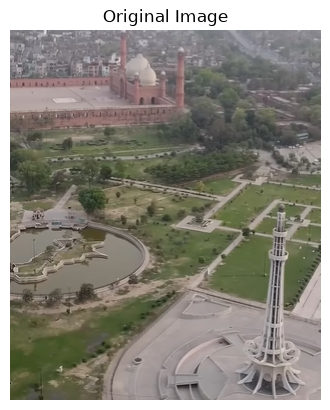

In [309]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [310]:
height, width, channels = img.shape
print("Height:", height)
print("Width:", width)
print("Channels:", channels)

Height: 370
Width: 311
Channels: 3


In [311]:
bright_img = cv2.convertScaleAbs(img, alpha=1.0, beta=50)
dark_img = cv2.convertScaleAbs(img, alpha=1.0, beta=-50)

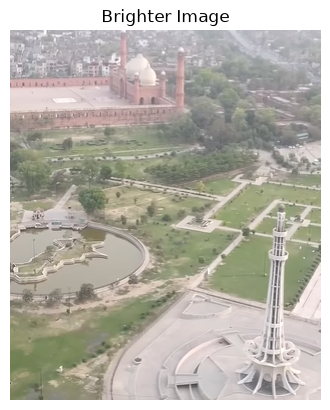

In [312]:
plt.imshow(cv2.cvtColor(bright_img, cv2.COLOR_BGR2RGB))
plt.title("Brighter Image")
plt.axis("off")
plt.show()

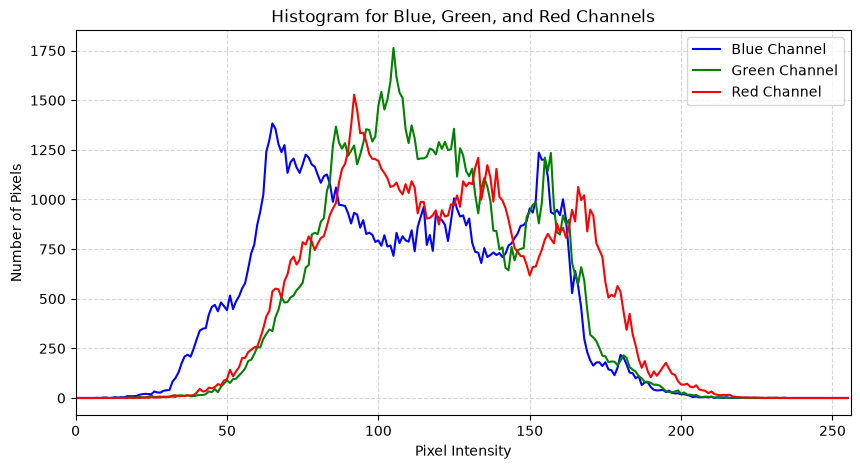

In [313]:
channels = cv2.split(img)
colors = ('b', 'g', 'r')
names = ('Blue Channel', 'Green Channel', 'Red Channel')

plt.figure(figsize=(10, 5))
plt.title("Histogram for Blue, Green, and Red Channels")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")

for i, (color, name) in enumerate(zip(colors, names)):
    hist = cv2.calcHist([img], [i], None, [256], [0, 256])
    plt.plot(hist, color=color, label=name)
    plt.xlim([0, 256])

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [314]:
noisy = img.copy()

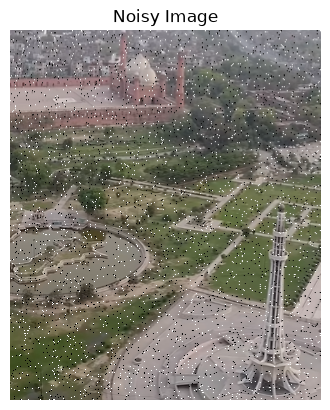

In [315]:
amount = 0.02
num_pixels = int(amount * img.shape[0] * img.shape[1])
y = np.random.randint(0, img.shape[0], num_pixels)
x = np.random.randint(0, img.shape[1], num_pixels)
noisy[y, x] = 255
y = np.random.randint(0, img.shape[0], num_pixels)
x = np.random.randint(0, img.shape[1], num_pixels)
noisy[y, x] = 0
plt.imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
plt.title("Noisy Image")
plt.axis("off")
plt.show()

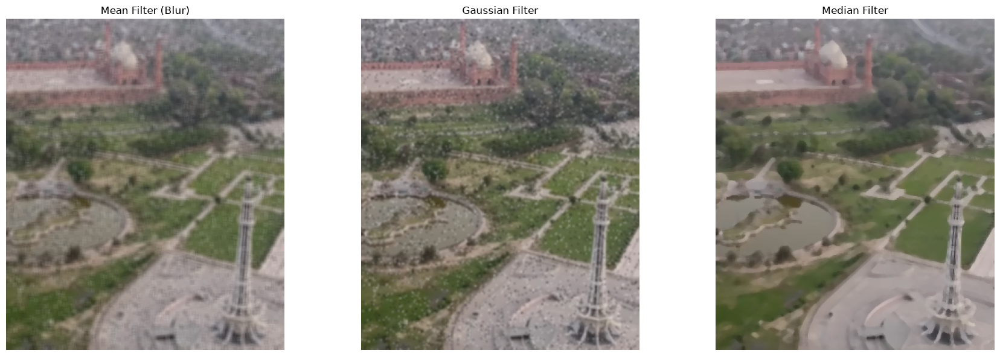

In [316]:
mean_filtered = cv2.blur(noisy, (5, 5))
gaussian_filtered = cv2.GaussianBlur(noisy, (5, 5), 0)
median_filtered = cv2.medianBlur(noisy, 5)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(mean_filtered, cv2.COLOR_BGR2RGB))
axes[0].set_title("Mean Filter (Blur)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(gaussian_filtered, cv2.COLOR_BGR2RGB))
axes[1].set_title("Gaussian Filter")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(median_filtered, cv2.COLOR_BGR2RGB))
axes[2].set_title("Median Filter")
axes[2].axis("off")

plt.tight_layout()
plt.show()

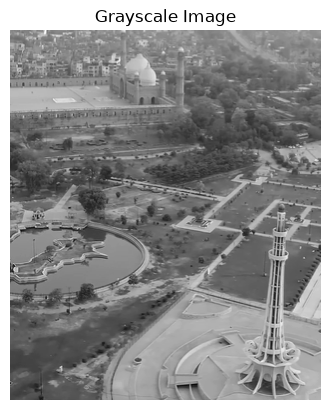

In [317]:
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray_img, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

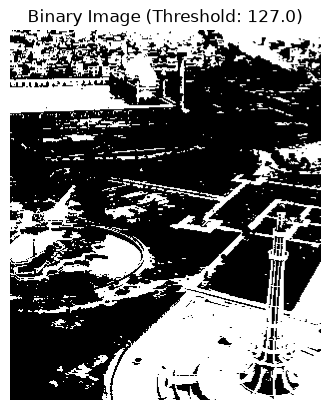

In [318]:
retval, binary_img = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)

plt.imshow(binary_img, cmap='gray')
plt.title(f"Binary Image (Threshold: {retval})")
plt.axis("off")
plt.show()

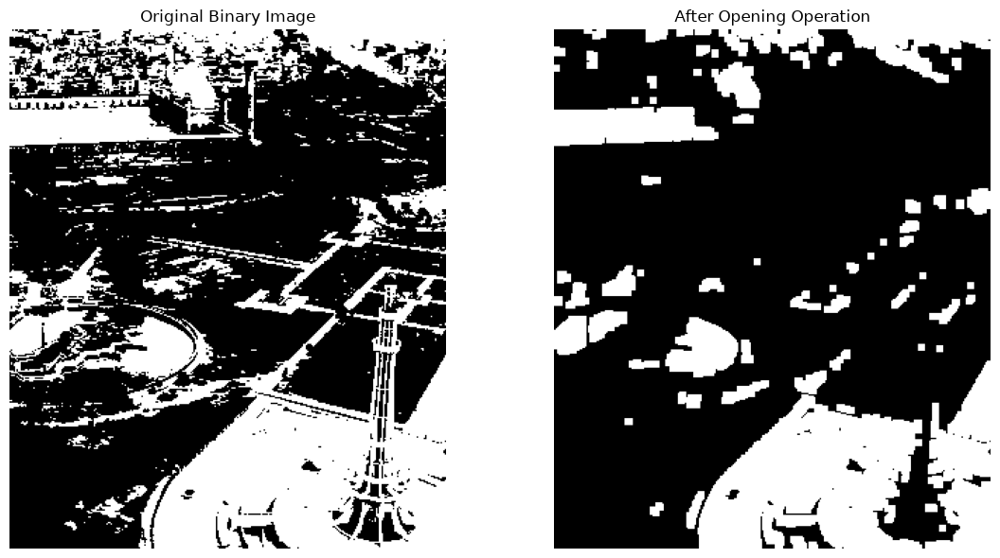

In [319]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

opened_img = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(binary_img, cmap='gray')
axes[0].set_title("Original Binary Image")
axes[0].axis("off")

axes[1].imshow(opened_img, cmap='gray')
axes[1].set_title("After Opening Operation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Total number of detected objects/regions: 438


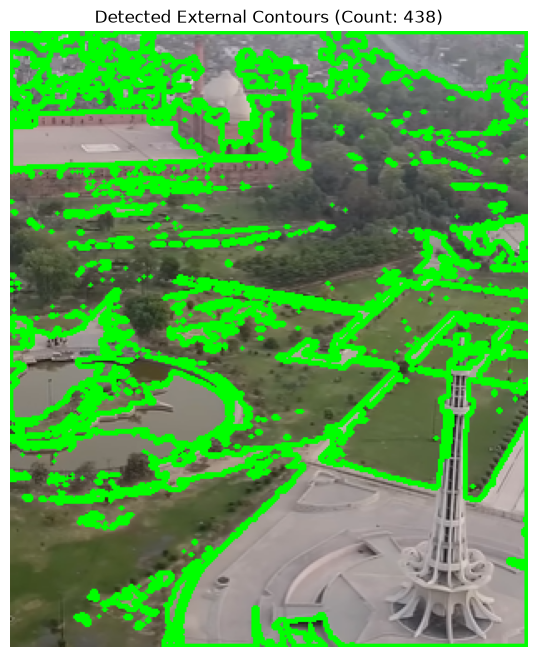

In [320]:
contours, hierarchy = cv2.findContours(binary_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

contour_img = img_rgb.copy()

cv2.drawContours(contour_img, contours, -1, (0, 255, 0), 2)

print(f"Total number of detected objects/regions: {len(contours)}")

plt.figure(figsize=(8, 8))
plt.imshow(contour_img)
plt.title(f"Detected External Contours (Count: {len(contours)})")
plt.axis("off")
plt.show()

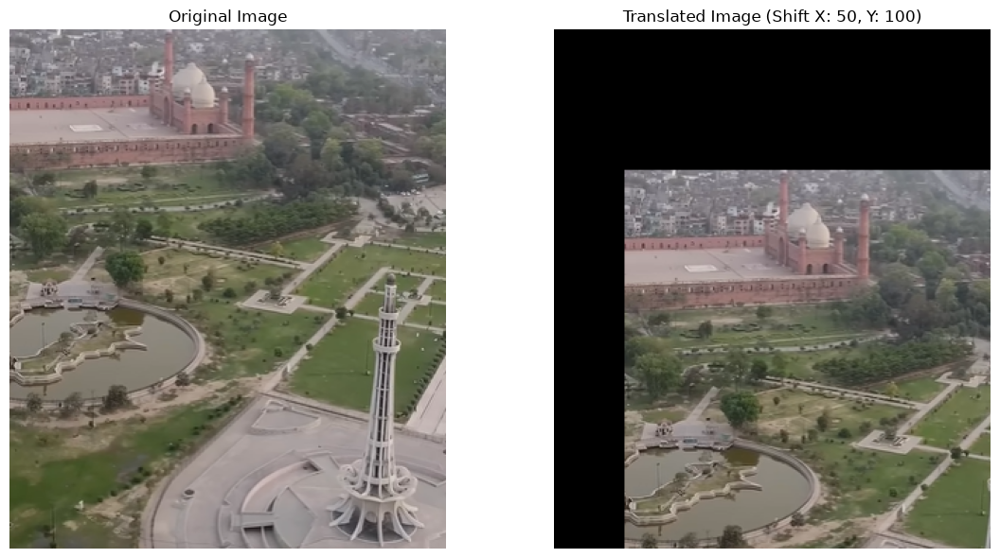

In [321]:
tx = 50
ty = 100
M = np.float32([[1, 0, tx], [0, 1, ty]])

translated_img = cv2.warpAffine(img_rgb, M, (width, height))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(translated_img)
axes[1].set_title(f"Translated Image (Shift X: {tx}, Y: {ty})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

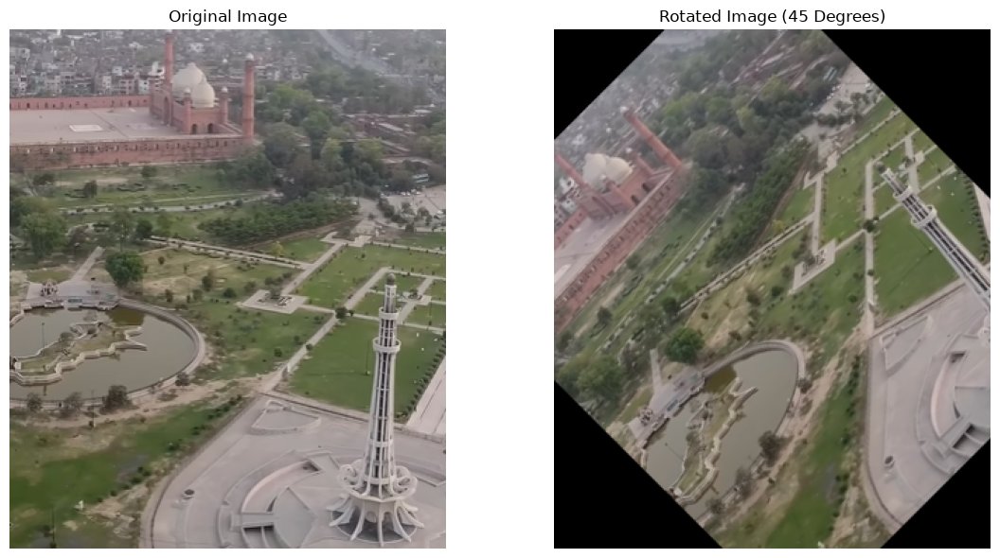

In [322]:
center = (width // 2, height // 2)
angle = 45
scale = 1.0

M_rotate = cv2.getRotationMatrix2D(center, angle, scale)

rotated_img = cv2.warpAffine(img_rgb, M_rotate, (width, height))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(rotated_img)
axes[1].set_title(f"Rotated Image ({angle} Degrees)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

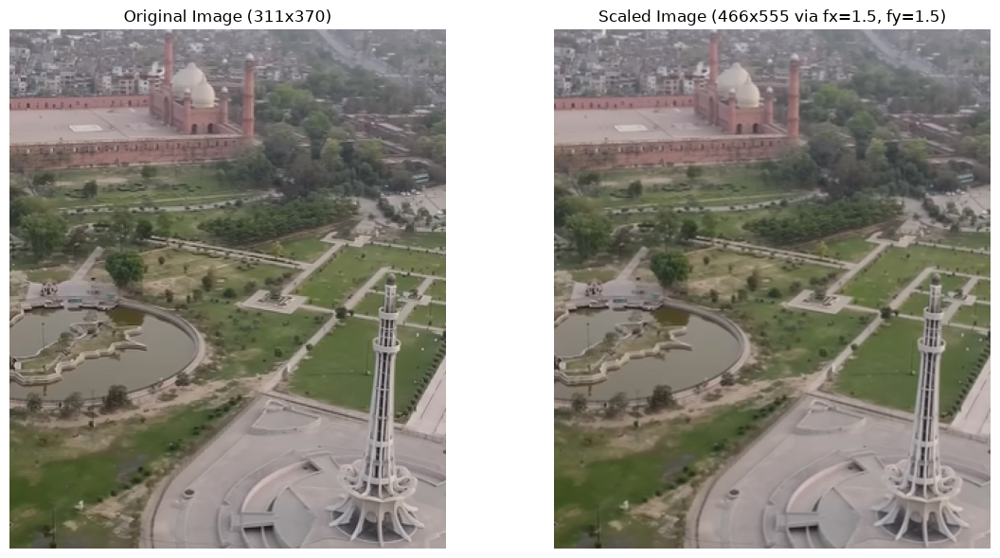

In [323]:

fx = 1.5
fy = 1.5

scaled_img = cv2.resize(img_rgb, None, fx=fx, fy=fy, interpolation=cv2.INTER_LINEAR)

h_scaled, w_scaled, _ = scaled_img.shape

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_rgb)
axes[0].set_title(f"Original Image ({width}x{height})")
axes[0].axis("off")

axes[1].imshow(scaled_img)
axes[1].set_title(f"Scaled Image ({w_scaled}x{h_scaled} via fx={fx}, fy={fy})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

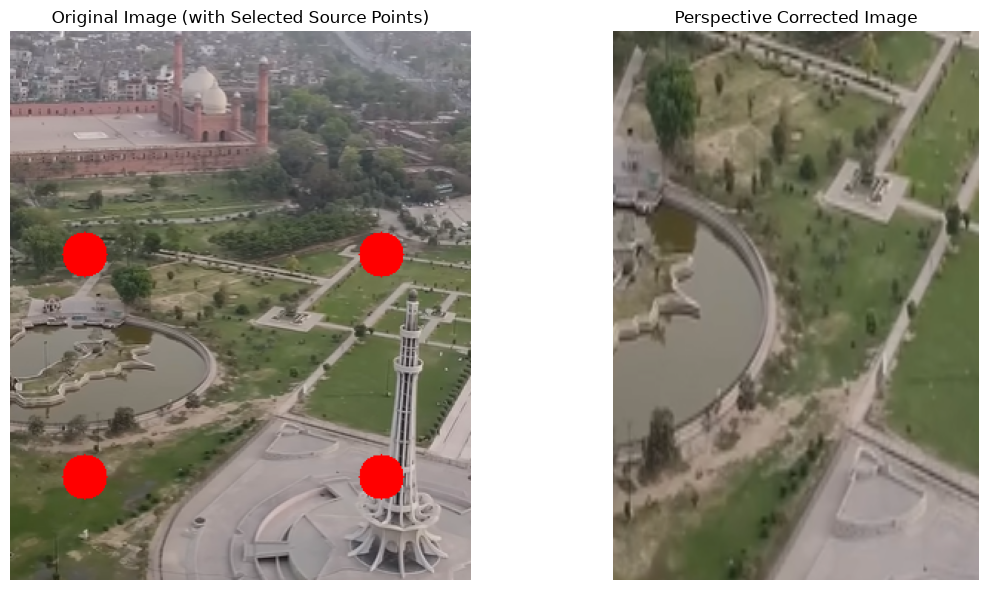

In [335]:
pts_src = np.float32([
    [50, 150],  
    [250, 150], 
    [50, 300],   
    [250, 300]   
])

width = 400
height = 600

pts_dst = np.float32([
    [0, 0],
    [width, 0],
    [0, height],
    [width, height]
])

M_perspective = cv2.getPerspectiveTransform(pts_src, pts_dst)
warped_img = cv2.warpPerspective(img_rgb, M_perspective, (width, height))

img_with_points = img_rgb.copy()
for pt in pts_src:
    cv2.circle(img_with_points, tuple(pt.astype(int)), 15, (255, 0, 0), -1)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_with_points)
axes[0].set_title("Original Image (with Selected Source Points)")
axes[0].axis("off")

axes[1].imshow(warped_img)
axes[1].set_title("Perspective Corrected Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

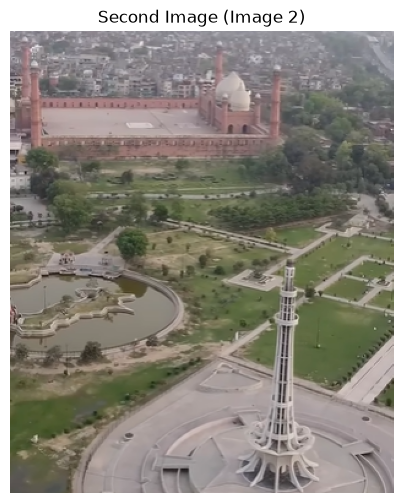

In [325]:
img2 = cv2.imread("m4.png")
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

height2, width2, channels2 = img2.shape

plt.figure(figsize=(6, 6))
plt.imshow(img2_rgb)
plt.title("Second Image (Image 2)")
plt.axis("off")
plt.show()

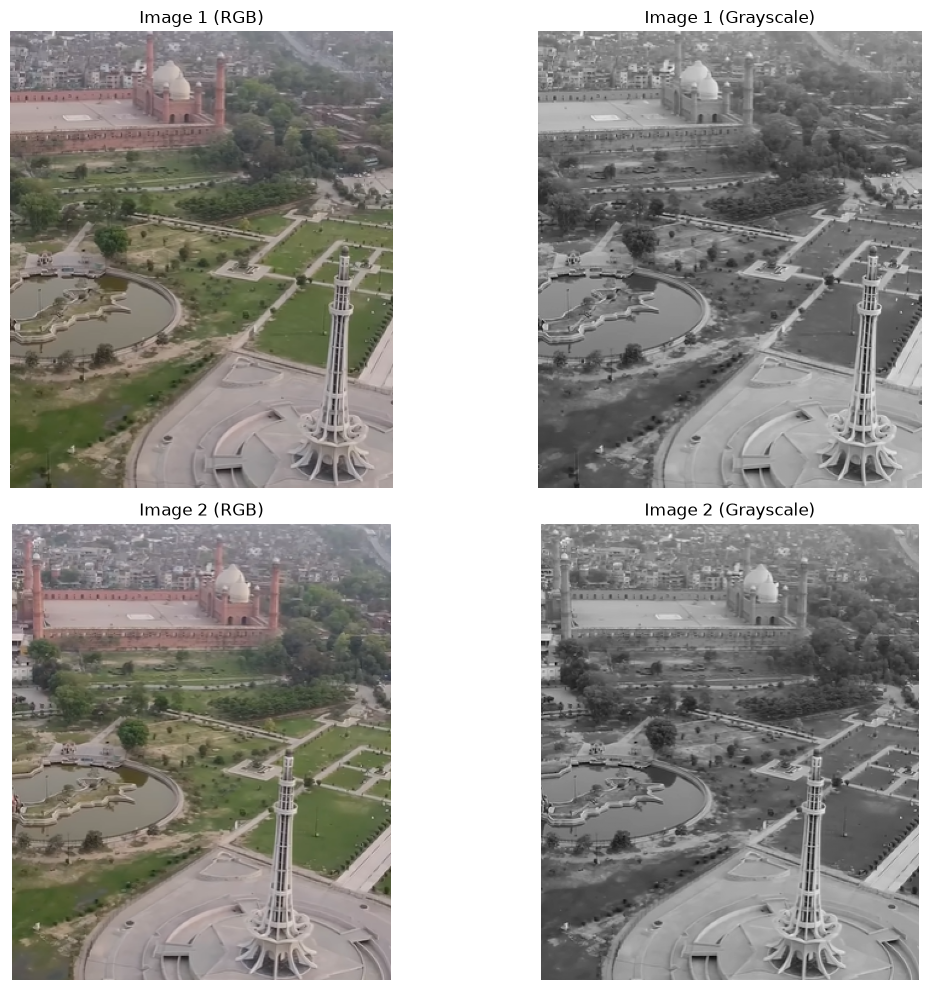

In [326]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title("Image 1 (RGB)")
axes[0, 0].axis("off")

axes[0, 1].imshow(gray_img, cmap='gray')
axes[0, 1].set_title("Image 1 (Grayscale)")
axes[0, 1].axis("off")

axes[1, 0].imshow(img2_rgb)
axes[1, 0].set_title("Image 2 (RGB)")
axes[1, 0].axis("off")

axes[1, 1].imshow(gray_img2, cmap='gray')
axes[1, 1].set_title("Image 2 (Grayscale)")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

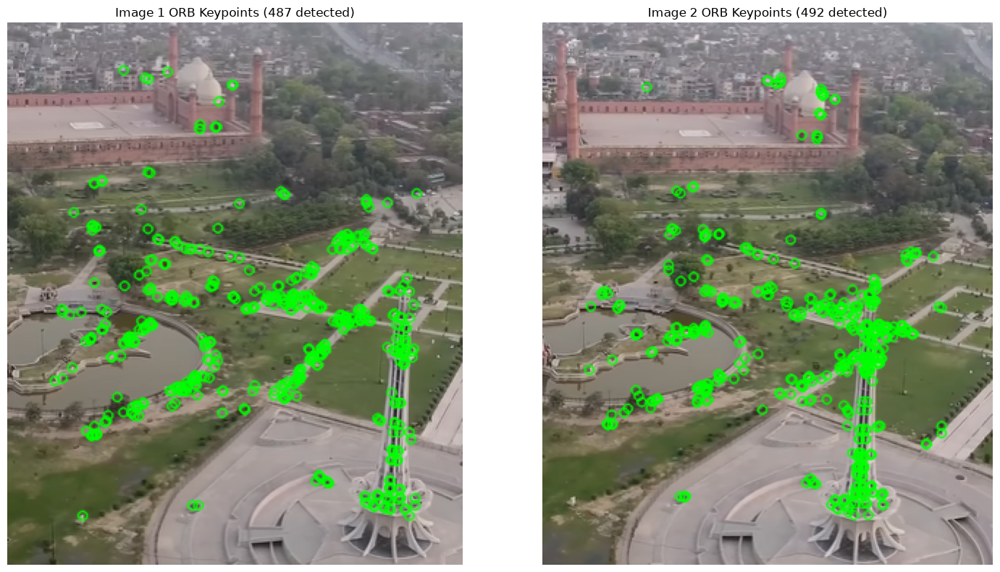

In [327]:
import cv2
import matplotlib.pyplot as plt

orb = cv2.ORB_create(nfeatures=500)

kp1, des1 = orb.detectAndCompute(gray_img, None)
kp2, des2 = orb.detectAndCompute(gray_img2, None)


img1_keypoints = cv2.drawKeypoints(img_rgb, kp1, None, color=(0, 255, 0), flags=0)
img2_keypoints = cv2.drawKeypoints(img2_rgb, kp2, None, color=(0, 255, 0), flags=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(img1_keypoints)
axes[0].set_title(f"Image 1 ORB Keypoints ({len(kp1)} detected)")
axes[0].axis("off")

axes[1].imshow(img2_keypoints)
axes[1].set_title(f"Image 2 ORB Keypoints ({len(kp2)} detected)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

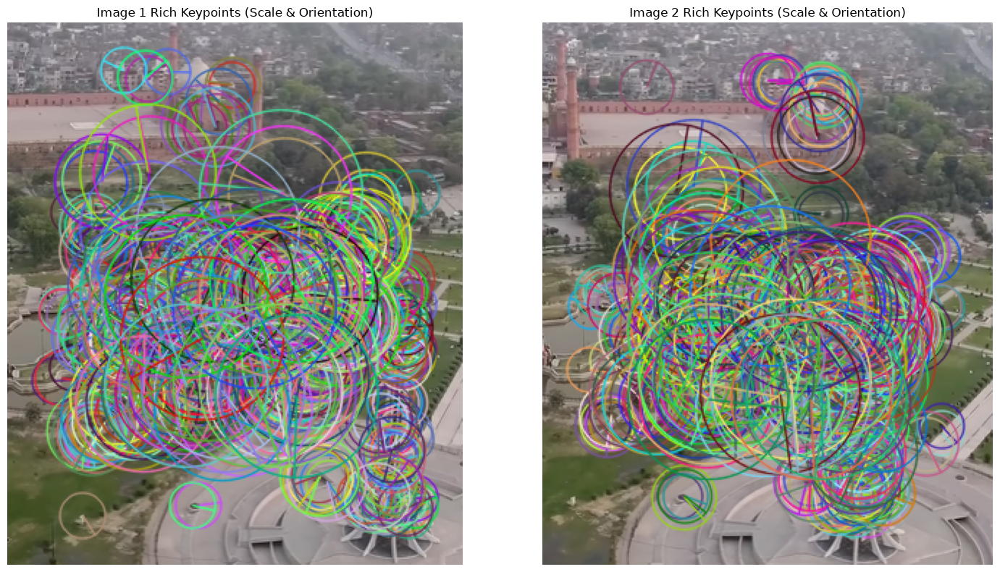

In [328]:
img1_rich_kp = cv2.drawKeypoints(img_rgb, kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
img2_rich_kp = cv2.drawKeypoints(img2_rgb, kp2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(img1_rich_kp)
axes[0].set_title("Image 1 Rich Keypoints (Scale & Orientation)")
axes[0].axis("off")

axes[1].imshow(img2_rich_kp)
axes[1].set_title("Image 2 Rich Keypoints (Scale & Orientation)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

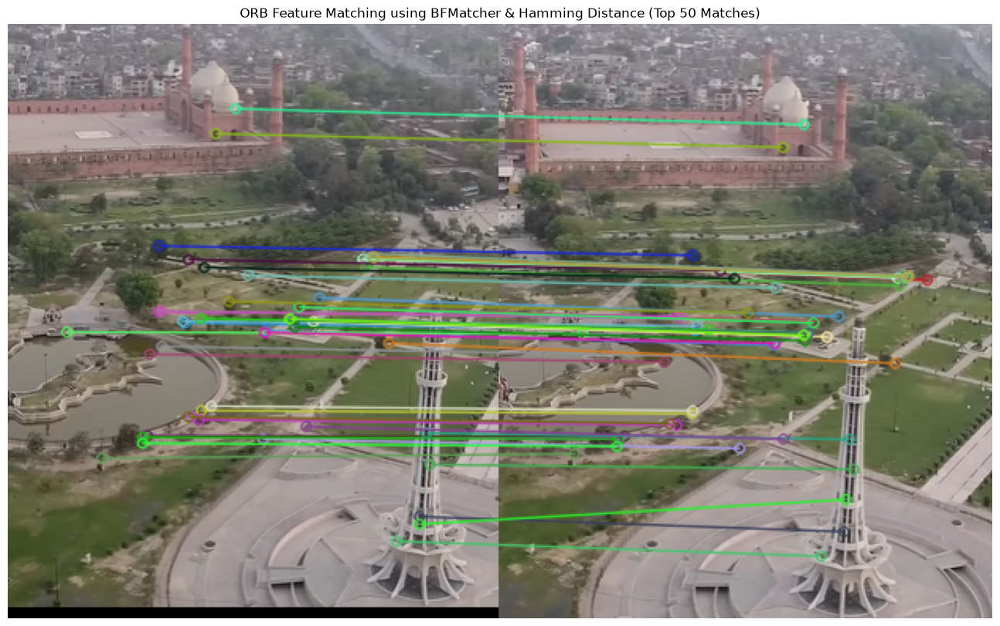

In [329]:
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

matches = bf.match(des1, des2)

matches = sorted(matches, key=lambda x: x.distance)

matching_result = cv2.drawMatches(
    img_rgb, kp1,
    img2_rgb, kp2,
    matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 10))
plt.imshow(matching_result)
plt.title(f"ORB Feature Matching using BFMatcher & Hamming Distance (Top 50 Matches)")
plt.axis("off")
plt.show()

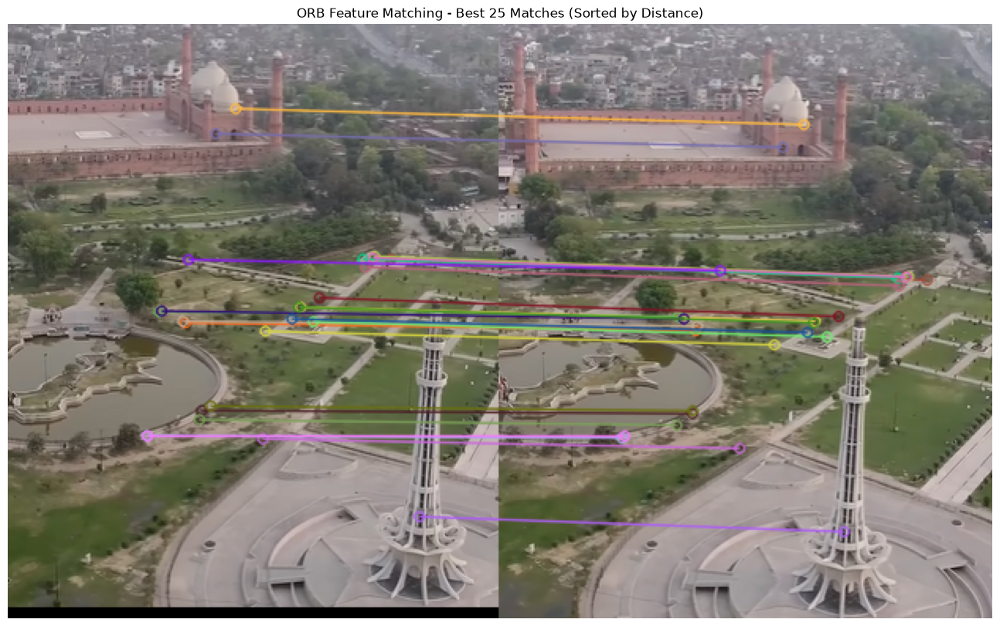

In [330]:
best_matches = matches[:25]

matching_result_best = cv2.drawMatches(
    img_rgb, kp1,
    img2_rgb, kp2,
    best_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 10))
plt.imshow(matching_result_best)
plt.title("ORB Feature Matching - Best 25 Matches (Sorted by Distance)")
plt.axis("off")
plt.show()

In [331]:
print(f"Total ORB keypoints detected in Image 1: {len(kp1)}")
print(f"Total ORB keypoints detected in Image 2: {len(kp2)}")
print(f"Total feature matches found between both images: {len(matches)}")

Total ORB keypoints detected in Image 1: 487
Total ORB keypoints detected in Image 2: 492
Total feature matches found between both images: 203
